In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense, Input, Dropout, LSTM
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the IMDB Dataset

num_words=10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=num_words
)

print(x_train.shape)
print(x_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(25000,)
(25000,)


In [5]:
print("First review:", x_train[0])
print("First sentiment:", y_train[0])

First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
First sentiment: 1


In [8]:
# Preprocess the Dataset (Padding)

max_length = 200

x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [11]:
# Build the LSTM Model

embedding_dim = 128

model = Sequential([
    Embedding(
        input_dim=num_words,
        output_dim=embedding_dim,
        input_length=max_length
    ),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile the Model

model.compile(
    optimizer="adam",
    metrics=["accuracy"],
    loss="binary_crossentropy"
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
hist = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    verbose=1,
    validation_split=0.2
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5206 - loss: 0.6953 - val_accuracy: 0.5552 - val_loss: 0.6829
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5875 - loss: 0.6618 - val_accuracy: 0.6166 - val_loss: 0.6260
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6048 - loss: 0.6420 - val_accuracy: 0.5368 - val_loss: 0.6806
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7158 - loss: 0.5620 - val_accuracy: 0.8022 - val_loss: 0.4788
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8137 - loss: 0.4330 - val_accuracy: 0.8392 - val_loss: 0.3810


In [14]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8283 - loss: 0.4021
Test Loss: 0.40208134055137634
Test Accuracy: 82.8279972076416 %


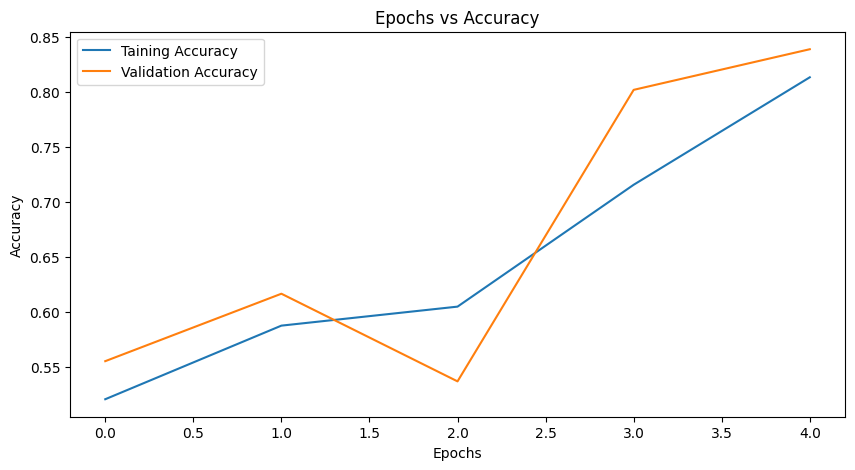

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(hist.history["accuracy"], label="Taining Accuracy")
plt.plot(hist.history["val_accuracy"], label="Validation Accuracy")

plt.title("Epochs vs Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

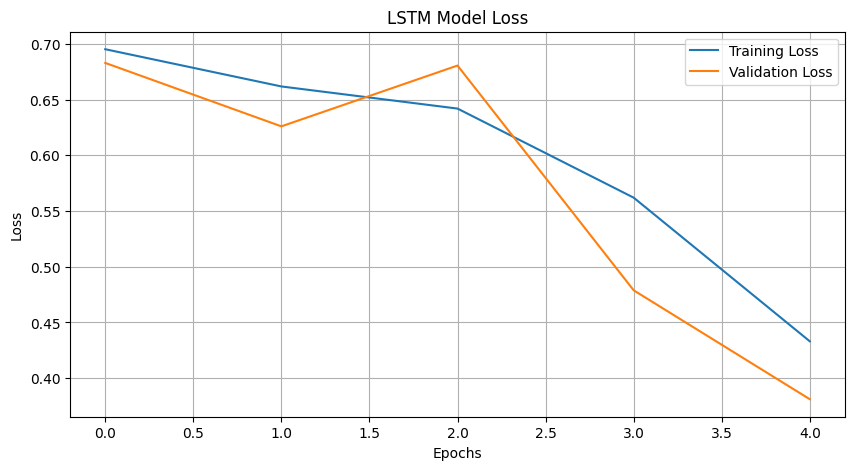

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(hist.history['loss'], label='Training Loss')
plt.plot(hist.history['val_loss'], label='Validation Loss')

plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Predict Sentiment on Test Data

y_pred_prob = model.predict(x_test)

y_pred = (y_pred_prob > 0.5).astype(int)

print("Predictions completed!")
print("Total predictions:", len(y_pred))

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Predictions completed!
Total predictions: 25000


In [19]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

              precision    recall  f1-score   support

    Negative       0.81      0.85      0.83     12500
    Positive       0.85      0.80      0.82     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



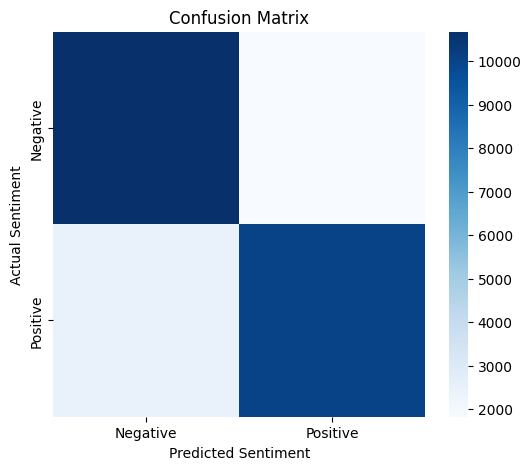

In [23]:
# Confusion Matrix Visualization

cm = confusion_matrix(y_test, y_pred)

import seaborn as sns
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()